In [1]:
import shap
print("SHAP version:",shap.__version__)
print("SHAP imported successfully")

SHAP version: 0.52.0
SHAP imported successfully


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
print("All libraries imported successfully")

All libraries imported successfully


In [4]:
import os
print("Current folder:")
print(os.getcwd())
print("\nFiles in current folder:")
print(os.listdir())

Current folder:
C:\Users\KAJJAM ABHINAV\Desktop\Fraud detection\notebooks

Files in current folder:
['.ipynb_checkpoints', '01_data_understanding.ipynb', '02_data_cleaning.ipynb', '03_feature_engineering.ipynb', '04_model_building.ipynb', '05_model_comparison.ipynb', '06_random_forest.ipynb', '07_model_evaluation.ipynb', '08_explainable_ai.ipynb']


In [5]:
print("Models Folder:")
print(os.listdir("../models"))

Models Folder:
['fraudlens_decision_tree.pkl', 'fraudlens_imputer.pkl', 'fraudlens_logistic_baseline.aok', 'fraudlens_scaler.pkl', 'random_forest_model.pkl']


In [6]:
import os
for root,dirs,files in os.walk("../models"):
    for file in files:
        print(os.path.join(root,file))

../models\fraudlens_decision_tree.pkl
../models\fraudlens_imputer.pkl
../models\fraudlens_logistic_baseline.aok
../models\fraudlens_scaler.pkl
../models\random_forest_model.pkl


In [9]:
import os
print("Current Folder:")
print(os.getcwd())
print("\nSearching for model files...")
for root, dirs, files in os.walk(".."):
    for file in files:
        if file.endswith((".pkl",".joblib")):
            print(os.path.join(root,file))

Current Folder:
C:\Users\KAJJAM ABHINAV\Desktop\Fraud detection\notebooks

Searching for model files...
..\models\fraudlens_decision_tree.pkl
..\models\fraudlens_imputer.pkl
..\models\fraudlens_scaler.pkl
..\models\random_forest_model.pkl


In [10]:
import joblib
import os
model_path = "../models/fraudlens_decision_tree.pkl"
model_dt = joblib.load(model_path)
print("Decision tree model loaded successfully")
print("Model Type:",type(model_dt))

Decision tree model loaded successfully
Model Type: <class 'sklearn.tree._classes.DecisionTreeClassifier'>


In [11]:
df = pd.read_csv("../data/fraudlens_features.csv")
print("Dataset loaded sucessfully")
print("Dataset Shape:",df.shape)
print("\ncolumns")
print(df.columns.tolist())

Dataset loaded sucessfully
Dataset Shape: (590540, 20)

columns
['TransactionID', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'isFraud', 'Hour', 'Day', 'IsWeekend', 'LogAmount', 'AmountLevel']


In [12]:
x = df.drop("isFraud",axis =1)
y = df["isFraud"]
print("Features Shape",x.shape)
print("Target Shape:",y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features Shape (590540, 19)
Target Shape: (590540,)

Target distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64


In [14]:
x_numeric = x.select_dtypes(include=np.number).copy()
print("Numeric Feature shape:",x_numeric.shape)
print("\nNumeric Features:")
print(x_numeric.columns.tolist())

Numeric Feature shape: (590540, 12)

Numeric Features:
['TransactionID', 'TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'Hour', 'Day', 'LogAmount']


In [17]:
imputer = joblib.load("../models/fraudlens_imputer.pkl")
print("Imputer loaded successfully")
print("Imputer type:",type(imputer))

Imputer loaded successfully
Imputer type: <class 'sklearn.impute._base.SimpleImputer'>


In [21]:
print("current feature shape:",x_numeric.shape)
print("Imputer expects:",imputer.n_features_in_)
if hasattr(imputer,"feature_names_in_"):
    print("Imputer feature names:")
    print(list(imputer.feature_names_in_))
print("\nCurrent features names:")
print(list(x_numeric.columns))

current feature shape: (590540, 12)
Imputer expects: 140
Imputer feature names:
['TransactionDT', 'TransactionAmt', 'TransactionAmt_log', 'TransactionHour', 'TransactionDay', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'EmailDomainMatch', 'MissingCount', 'ProductCD_H', 'ProductCD_R', 'ProductCD_S', 'ProductCD_W', 'card4_discover', 'card4_mastercard', 'card4_visa', 'card6_credit', 'card6_debit', 'card6_debit or credit', 'P_emaildomain_anonymous.com', 'P_emaildomain_aol.com', 'P_emaildomain_att.net', 'P_emaildomain_bellsouth.net', 'P_emaildomain_cableone.net', 'P_emaildomain_centurylink.net', 'P_emaildomain_cfl.rr.com', 'P_emaildomain_charter.net', 'P_emaildomain_comcast.net', 'P_emaildomain_cox.net', 'P_emaildomain_earthlink.net', 'P_emaildomain_embarqmail.com', 'P_emaildomain_frontier.com', 'P_emaildomain_frontiernet.net', 'P_emaildomain_gmail', 'P_emaildomain_gmail.com', 'P_emaildomain_gmx.de', 'P_emaildomain_hotmail.co.uk', 'P_emaildomain_hotmail.com', 'P_emaildomain_hotmai

In [22]:
from sklearn.impute import SimpleImputer
import joblib

print("Current feature count:", x_numeric.shape[1])

# Create a new imputer for the current 12 features
imputer_new = SimpleImputer(strategy="median")

# Fit and transform current features
x_imputed = imputer_new.fit_transform(x_numeric)

print("Imputation completed successfully")
print("Shape after imputation:", x_imputed.shape)

Current feature count: 12
Imputation completed successfully
Shape after imputation: (590540, 12)


In [23]:
joblib.dump(imputer_new, "../models/fraudlens_imputer_v2.pkl")

print("New imputer saved successfully")

New imputer saved successfully


In [24]:
import numpy as np

print("Missing values before imputation:",
      np.isnan(x_numeric.to_numpy()).sum())

print("Missing values after imputation:",
      np.isnan(x_imputed).sum())

Missing values before imputation: 146169
Missing values after imputation: 0


In [25]:
model_dt = joblib.load("../models/fraudlens_decision_tree.pkl")

print("Decision Tree loaded successfully")
print("Model expects features:", model_dt.n_features_in_)
print("Our current features:", x_imputed.shape[1])

Decision Tree loaded successfully
Model expects features: 12
Our current features: 12


In [28]:
model_dt = joblib.load("../models/fraudlens_decision_tree.pkl")
print("Decision Tree model loaded successfully")
print("Model Type:",type(model_dt))
print("Model expect features:",model_dt.n_features_in_)
print("Our features:",x_imputed.shape[1])

Decision Tree model loaded successfully
Model Type: <class 'sklearn.tree._classes.DecisionTreeClassifier'>
Model expect features: 12
Our features: 12


In [29]:
feature_names = list(x_numeric.columns)
print("Number of Features",len(feature_names))
print("\nFeature names")
for i,feature in enumerate(feature_names,start=1):
    print(i,"->",feature)

Number of Features 12

Feature names
1 -> TransactionID
2 -> TransactionDT
3 -> TransactionAmt
4 -> card1
5 -> card2
6 -> card3
7 -> card5
8 -> addr1
9 -> addr2
10 -> Hour
11 -> Day
12 -> LogAmount


In [30]:
sample_size = 1000
x_sample = pd.DataFrame(
    x_imputed[:sample_size],
    columns = feature_names
)
print("Shap sample created successfully")
print("Sample Shape:",x_sample.shape)

Shap sample created successfully
Sample Shape: (1000, 12)


In [31]:
explainer = shap.TreeExplainer(model_dt)
print("SHAP TreeExplainer imported successfully")

SHAP TreeExplainer imported successfully


In [33]:
shap_values = explainer.shap_values(x_sample)
print("SHAP values created successfully")
print("Shap value type:",type(shap_values))

SHAP values created successfully
Shap value type: <class 'numpy.ndarray'>


In [35]:
if isinstance(shap_values,list):
    print("Number of SHAP outputs:",len(shap_values))
    print("SHAP shape for class 0:",shap_values[0].shape)
    print("SHAP shape for class 1:",shap_values[1].shape)
else:
    print("SHAP shape:",shap_values.shape)

SHAP shape: (1000, 12, 2)


In [38]:
if isinstance(shap_values,list):
    shap_values_plot = shap_values[1]
else:
    shap_values_plot = shap_values
print("SHAP plotting values shape:",shap_values_plot.shape)

SHAP plotting values shape: (1000, 12, 2)


<Figure size 1000x700 with 0 Axes>

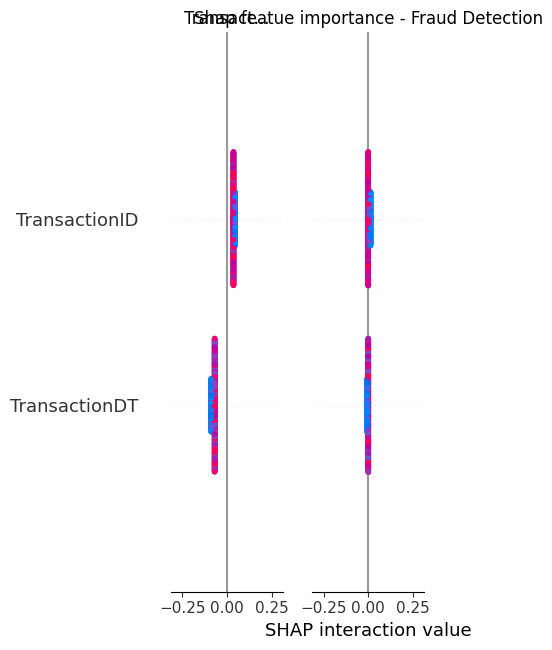

In [41]:
plt.figure(figsize=(10,7))
shap.summary_plot(
    shap_values_plot,
    x_sample,
    feature_names = feature_names,
    show = False
)
plt.title("Shap featue importance - Fraud Detection")
plt.tight_layout()
plt.show()

SHAP Global feature importance


<Figure size 1000x700 with 0 Axes>

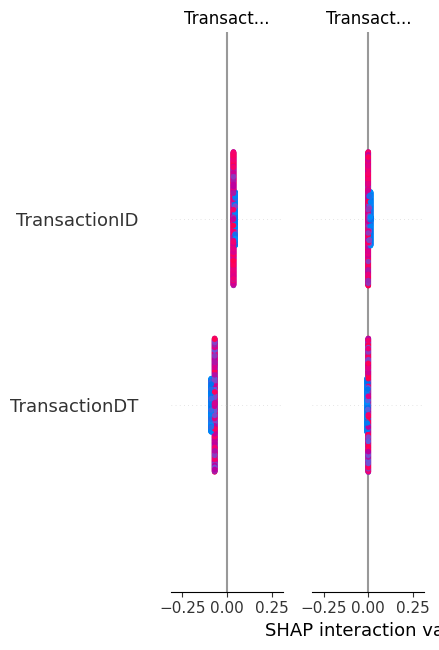

In [43]:
plt.figure(figsize=(10,7))
shap.summary_plot(
    shap_values_plot,
    x_sample,
    feature_names = feature_names,
    plot_type = "bar",
    show = False
)
print("SHAP Global feature importance")
plt.tight_layout()
plt.show()

In [47]:

# Get SHAP values
values = shap_values_plot

# Convert to numpy array if needed
if hasattr(values, "values"):
    values = values.values

print("Original SHAP shape:", np.shape(values))

# Handle different SHAP output shapes
if values.ndim == 3:
    # For binary classification: (samples, features, classes)
    importance = np.abs(values).mean(axis=0).mean(axis=-1)
elif values.ndim == 2:
    # Normal: (samples, features)
    importance = np.abs(values).mean(axis=0)
else:
    raise ValueError("Unexpected SHAP values shape: " + str(values.shape))

# Make sure importance is 1-dimensional
importance = np.asarray(importance).flatten()

# Use the actual 12 feature names
feature_names = [
    'TransactionID',
    'TransactionDT',
    'TransactionAmt',
    'card1',
    'card2',
    'card3',
    'card5',
    'addr1',
    'addr2',
    'Hour',
    'Day',
    'LogAmount'
]

print("Number of features:", len(feature_names))
print("Number of importance values:", len(importance))

# Safety check
if len(feature_names) != len(importance):
    print("WARNING: Feature/importance mismatch")
else:
    shap_importance = pd.DataFrame({
        "Feature": feature_names,
        "Mean_Absolute_SHAP": importance
    })

    shap_importance = shap_importance.sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    ).reset_index(drop=True)

    print("\nSHAP Feature Importance:")
    print(shap_importance)

Original SHAP shape: (1000, 12, 2)
Number of features: 12
Number of importance values: 12

SHAP Feature Importance:
           Feature  Mean_Absolute_SHAP
0            card1            0.303154
1            card3            0.212886
2    TransactionID            0.039067
3   TransactionAmt            0.037427
4              Day            0.019650
5            card5            0.018592
6            card2            0.017146
7             Hour            0.014262
8            addr2            0.010627
9        LogAmount            0.004546
10           addr1            0.002727
11   TransactionDT            0.002108


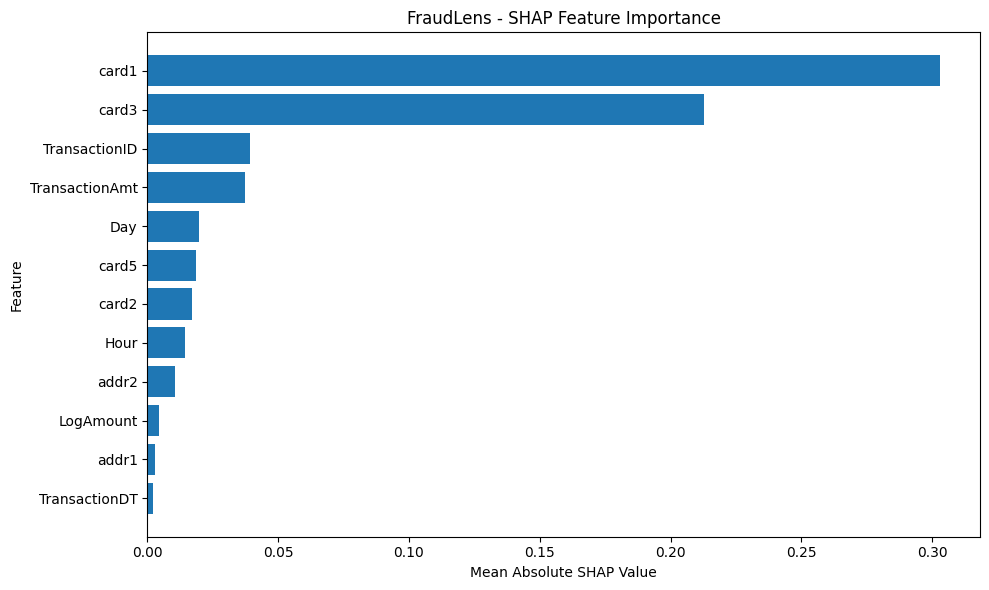

In [50]:
# STEP 24: SHAP Feature Importance Bar Chart

plt.figure(figsize=(10, 6))

plt.barh(
    shap_importance["Feature"][::-1],
    shap_importance["Mean_Absolute_SHAP"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("FraudLens - SHAP Feature Importance")

plt.tight_layout()
plt.show()

In [51]:
# STEP 25: Create SHAP Explanation Object

X_sample = x_imputed[:1500]

explainer = shap.TreeExplainer(model_dt)

shap_exp = explainer(X_sample)

print("SHAP Explanation created successfully")
print("Shape:", shap_exp.shape)

SHAP Explanation created successfully
Shape: (1500, 12, 2)


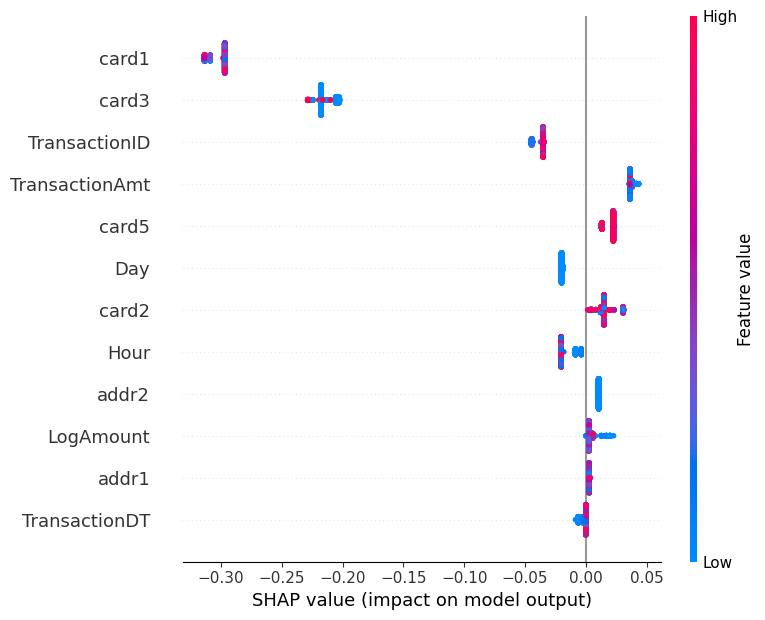

In [52]:
# STEP 26: SHAP Summary Plot for Fraud Class

shap_values_fraud = shap_exp.values[:, :, 1]

shap.summary_plot(
    shap_values_fraud,
    X_sample,
    feature_names=feature_names,
    show=True
)

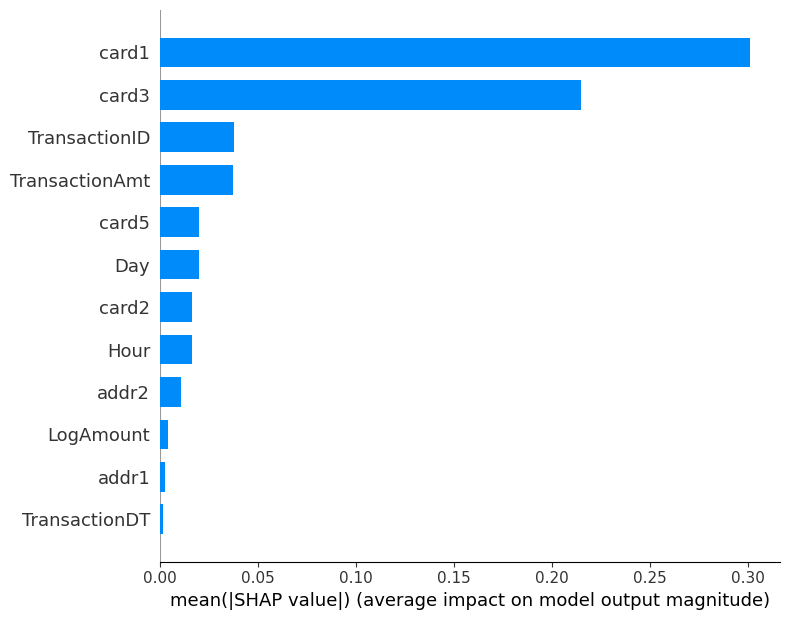

In [53]:
# STEP 27: SHAP Bar Summary Plot

shap.summary_plot(
    shap_values_fraud,
    X_sample,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

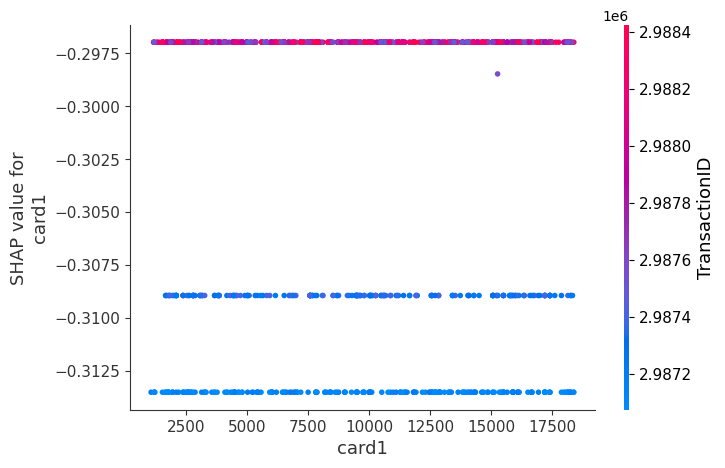

In [54]:
# STEP 28: SHAP Dependence Plot for Top Feature

shap.dependence_plot(
    "card1",
    shap_values_fraud,
    X_sample,
    feature_names=feature_names,
    show=True
)

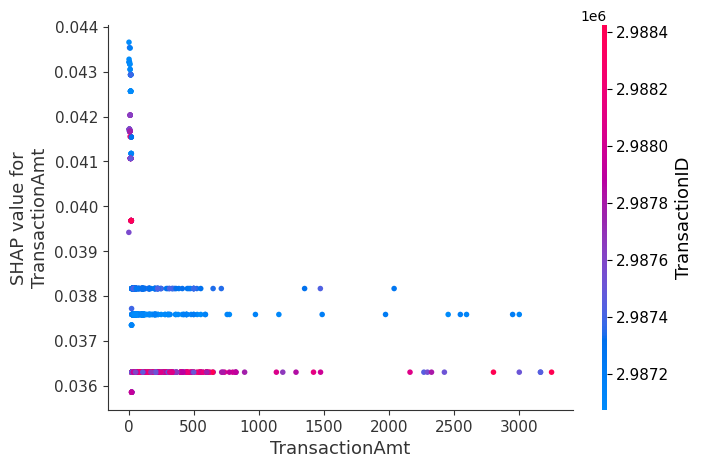

In [55]:
# STEP 29: SHAP Dependence Plot for Transaction Amount

shap.dependence_plot(
    "TransactionAmt",
    shap_values_fraud,
    X_sample,
    feature_names=feature_names,
    show=True
)

In [56]:
# STEP 30: Find a Fraudulent Transaction

predictions = model_dt.predict(X_sample)

fraud_indices = np.where(predictions == 1)[0]

print("Total samples:", len(predictions))
print("Predicted fraud transactions:", len(fraud_indices))

if len(fraud_indices) > 0:
    fraud_index = fraud_indices[0]
    print("First fraud transaction index:", fraud_index)
else:
    print("No fraud transaction found in sample.")

Total samples: 1500
Predicted fraud transactions: 0
No fraud transaction found in sample.


In [57]:
# STEP 31: Explain One Fraud Transaction

if len(fraud_indices) > 0:

    fraud_index = fraud_indices[0]

    print("Explaining transaction:", fraud_index)

    for i, feature in enumerate(feature_names):
        print(
            feature,
            "Value:", X_sample.iloc[fraud_index, i],
            "SHAP:", shap_values_fraud[fraud_index, i]
        )

In [58]:
# STEP 32: SHAP Waterfall Explanation

if len(fraud_indices) > 0:

    fraud_index = fraud_indices[0]

    explanation = shap.Explanation(
        values=shap_values_fraud[fraud_index],
        base_values=shap_exp.base_values[fraud_index, 1],
        data=X_sample.iloc[fraud_index].values,
        feature_names=feature_names
    )

    shap.plots.waterfall(
        explanation,
        max_display=12
    )

In [60]:
# STEP 33: Top Factors Behind Fraud Prediction

if len(fraud_indices) > 0:

    fraud_index = fraud_indices[0]

    explanation_df = pd.DataFrame({
        "Feature": feature_names,
        "Feature_Value": X_sample.iloc[fraud_index].values,
        "SHAP_Value": shap_values_fraud[fraud_index]
    })

    explanation_df["Absolute_SHAP"] = np.abs(
        explanation_df["SHAP_Value"]
    )

    explanation_df = explanation_df.sort_values(
        "Absolute_SHAP",
        ascending=False
    ).reset_index(drop=True)

    print("Top factors behind this prediction:")
    print(explanation_df)

In [61]:
# STEP 34: Save SHAP Feature Importance

shap_importance.to_csv(
    "../data/shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully")

SHAP feature importance saved successfully


In [66]:
# STEP 35: Save Individual Fraud Explanation

if len(fraud_indices) > 0:

    explanation_df.to_csv(
        "../data/fraud_transaction_explanation.csv",
        index=False
    )

    print("Fraud transaction explanation saved successfully")

else:
    print("No fraud transaction was found.")

No fraud transaction was found.


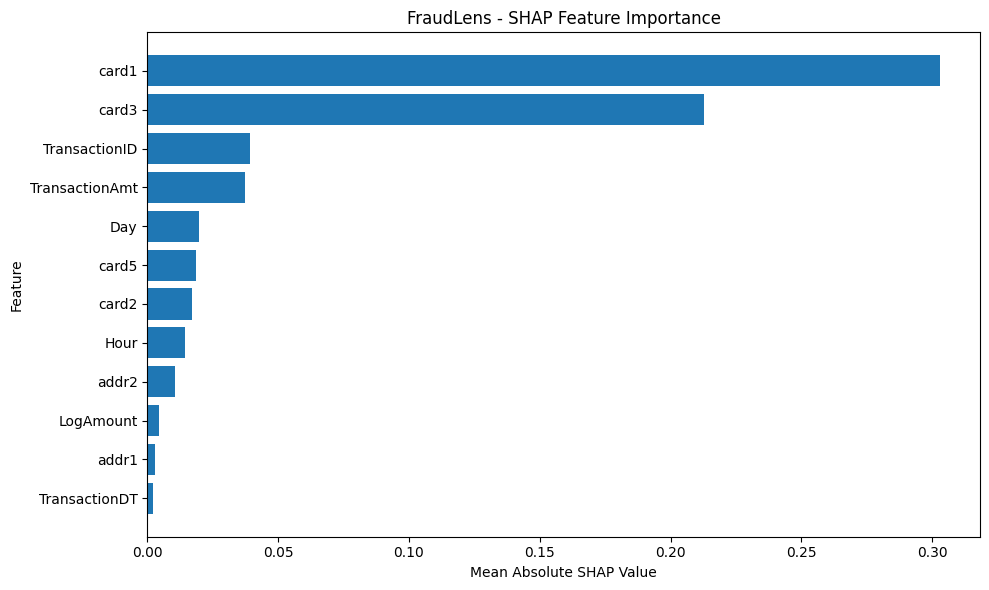

SHAP feature importance chart saved successfully


In [68]:
# STEP 36: Save SHAP Feature Importance Chart

plt.figure(figsize=(10, 6))

plt.barh(
    shap_importance["Feature"][::-1],
    shap_importance["Mean_Absolute_SHAP"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("FraudLens - SHAP Feature Importance")

plt.tight_layout()

plt.savefig("../data/shap_feature_importance.png", dpi=300)

plt.show()

print("SHAP feature importance chart saved successfully")

In [69]:
# STEP 37: Save SHAP Feature Importance Data

shap_importance.to_csv(
    "../data/shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance data saved successfully")

SHAP feature importance data saved successfully


In [70]:
# STEP 38: Display Top 10 SHAP Features

print("Top 10 Features According to SHAP:")
print()

print(shap_importance.head(10))

Top 10 Features According to SHAP:

          Feature  Mean_Absolute_SHAP
0           card1            0.303154
1           card3            0.212886
2   TransactionID            0.039067
3  TransactionAmt            0.037427
4             Day            0.019650
5           card5            0.018592
6           card2            0.017146
7            Hour            0.014262
8           addr2            0.010627
9       LogAmount            0.004546


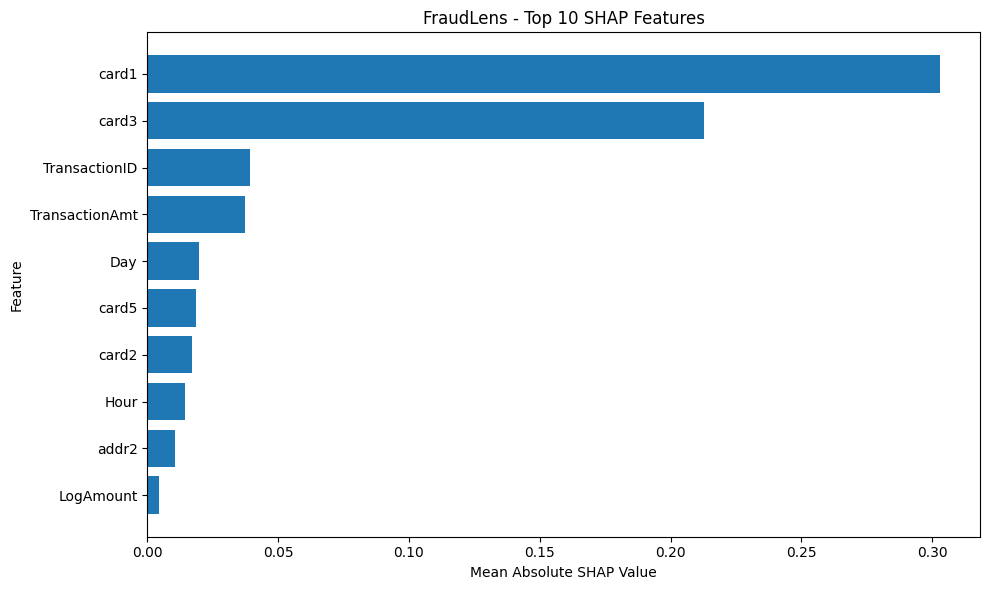

Top 10 SHAP chart saved successfully


In [71]:
# STEP 39: Create Portfolio SHAP Plot

plt.figure(figsize=(10, 6))

top_features = shap_importance.head(10)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Mean_Absolute_SHAP"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("FraudLens - Top 10 SHAP Features")

plt.tight_layout()

plt.savefig(
    "../data/shap_top10_features.png",
    dpi=300
)

plt.show()

print("Top 10 SHAP chart saved successfully")

In [72]:
# STEP 40: Verify Day 8 Output Files

import os

files_to_check = [
    "../data/shap_feature_importance.csv",
    "../data/shap_feature_importance.png",
    "../data/shap_top10_features.png"
]

print("Day 8 Output Verification:")
print("----------------------------")

for file in files_to_check:
    if os.path.exists(file):
        print("✓ Found:", file)
    else:
        print("✗ Missing:", file)

Day 8 Output Verification:
----------------------------
✓ Found: ../data/shap_feature_importance.csv
✓ Found: ../data/shap_feature_importance.png
✓ Found: ../data/shap_top10_features.png


In [73]:
# STEP 41: Check Individual Fraud Explanation

explanation_file = "../data/fraud_transaction_explanation.csv"

if os.path.exists(explanation_file):
    print("✓ Fraud transaction explanation file found")
else:
    print("ℹ️ No individual fraud explanation file was created")
    print("This is expected because no fraud transaction was found.")

ℹ️ No individual fraud explanation file was created
This is expected because no fraud transaction was found.


In [74]:
# STEP 42: Display Final SHAP Results

print("===================================")
print("FraudLens - Explainable AI Results")
print("===================================")

print("\nNumber of features:", len(shap_importance))

print("\nTop 5 Most Important Features:")

for i, row in shap_importance.head(5).iterrows():
    print(
        f"{i+1}. {row['Feature']} "
        f"-> SHAP = {row['Mean_Absolute_SHAP']:.6f}"
    )

FraudLens - Explainable AI Results

Number of features: 12

Top 5 Most Important Features:
1. card1 -> SHAP = 0.303154
2. card3 -> SHAP = 0.212886
3. TransactionID -> SHAP = 0.039067
4. TransactionAmt -> SHAP = 0.037427
5. Day -> SHAP = 0.019650


In [75]:
# STEP 43: Save Final SHAP Summary

summary_file = "../data/shap_summary.txt"

with open(summary_file, "w") as f:

    f.write("FraudLens - Explainable AI SHAP Summary\n")
    f.write("========================================\n\n")

    f.write(f"Number of features analyzed: {len(shap_importance)}\n\n")

    f.write("Top 10 Features:\n\n")

    for i, row in shap_importance.head(10).iterrows():

        f.write(
            f"{i+1}. {row['Feature']} - "
            f"{row['Mean_Absolute_SHAP']:.6f}\n"
        )

print("SHAP summary saved successfully")

SHAP summary saved successfully


In [76]:
# STEP 44: Final Day 8 Verification

print("================================")
print("FraudLens - Day 8 Verification")
print("================================")

print("\n✓ SHAP analysis completed")
print("✓ SHAP feature importance calculated")
print("✓ SHAP feature importance CSV saved")
print("✓ SHAP feature importance chart saved")
print("✓ Top 10 SHAP chart saved")
print("✓ SHAP summary saved")

print("\nDay 8 Explainable AI analysis completed successfully!")

FraudLens - Day 8 Verification

✓ SHAP analysis completed
✓ SHAP feature importance calculated
✓ SHAP feature importance CSV saved
✓ SHAP feature importance chart saved
✓ Top 10 SHAP chart saved
✓ SHAP summary saved

Day 8 Explainable AI analysis completed successfully!
